In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
pd.set_option('display.width',800)
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',800)

# pipeline function

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

def impute_and_normalize_data(data, target_cols):
    data_clean_before_imputation = data
    data_clean_before_imputation.reset_index(drop=True, inplace=True)
    targets = data_clean_before_imputation[target_cols]

    data_clean_before_imputation = data_clean_before_imputation.drop(target_cols, axis=1)

    # Separate quantitative and qualitative columns
    quantitative_columns = data_clean_before_imputation.select_dtypes(include=['int64', 'float64']).columns
    qualitative_columns = data_clean_before_imputation.select_dtypes(include=['object']).columns

    # Normalize and impute missing values in quantitative columns
    quantitative_data = data_clean_before_imputation[quantitative_columns]
    scaler = StandardScaler()
    quantitative_data_normalized = pd.DataFrame(scaler.fit_transform(quantitative_data), columns=quantitative_columns)
    imputer = KNNImputer(n_neighbors=5)
    quantitative_data_imputed_normalized = imputer.fit_transform(quantitative_data_normalized)
    quantitative_data_imputed = pd.DataFrame(scaler.inverse_transform(quantitative_data_imputed_normalized), columns=quantitative_columns)

    # Combine imputed quantitative columns and qualitative columns
    data_imputed = pd.concat([quantitative_data_imputed.reset_index(drop=True), data_clean_before_imputation[qualitative_columns].reset_index(drop=True)], axis=1)

    # Add the target columns back and remove rows where the targets are missing
    for col in target_cols:
        data_imputed[col] = targets[col]

    data_imputed = data_imputed.dropna(subset=target_cols)

    return data_imputed

In [152]:
%matplotlib inline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, TransformerMixin
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

class ShiftToPositive(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.min_ = pd.DataFrame(X).min()
        return self

    def transform(self, X):
        X_shifted = pd.DataFrame(X) - self.min_ + 1
        if np.any(np.isnan(X_shifted)) or np.any(np.isinf(X_shifted)):
            raise ValueError('NaN or infinity produced in ShiftToPositive transformation')
        return X_shifted.values


class SignedLogTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_transformed = np.sign(X) * np.log1p(np.abs(X))
        if np.any(np.isnan(X_transformed)) or np.any(np.isinf(X_transformed)):
            raise ValueError('NaN or infinity produced in signed logarithm transformation')
        return X_transformed


def plot_hist_before_after_transformation(X_train, col_name, transformer):
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.histplot(X_train[col_name], kde=True)
    plt.title(f'Before Transformation - {col_name}')

    X_train_transformed = transformer.fit_transform(X_train[[col_name]])

    plt.subplot(1, 2, 2)
    sns.histplot(X_train_transformed, kde=True)
    plt.title(f'After Transformation - {col_name}')

    plt.tight_layout()
    plt.show()

def run_modeling_pipeline(df, target_col, show_graphs=True, random_seed=42, ridge_alpha=np.logspace(-3, 3, 7), lasso_alpha=np.logspace(-3, 3, 7), tol=[1e-3, 1e-4, 1e-5], rf_max_depth=[8,10], rf_min_samples_split=[2,3], rf_min_samples_leaf=[1,3], rf_ccp_alpha=[1e-4, 1e-5, 1e-6], gbr_n_estimators=[100, 200, 300], gbr_learning_rate=[0.01, 0.1, 1], gbr_max_depth=[3, 4, 5], gbr_min_samples_split=[2, 3, 4], gbr_min_samples_leaf=[1, 2, 3], ridge_max_iter=1000, lasso_max_iter=1000):
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(include=[object, pd.Categorical]).columns.tolist()

    shifter = ShiftToPositive()
    log_transformer = SignedLogTransformer()

    if show_graphs:
        for col_name in num_cols:
            plot_hist_before_after_transformation(X_train, col_name, Pipeline(steps=[("shifter", shifter), ("log_transformer", log_transformer)]))

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[("shifter", shifter), ("log_transformer", log_transformer), ("scaler", MinMaxScaler())]), num_cols),
            ("cat", OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ]
    )

    pipe_ridge = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor",  Ridge(max_iter=ridge_max_iter)),
        ]
    )

    pipe_lasso = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", Lasso(max_iter=lasso_max_iter)),
        ]
    )


    pipe_rf = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor()),
        ]
    )

    pipe_gbr = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", GradientBoostingRegressor(random_state=random_seed)),
        ]
    )

    param_grid_ridge = {
        "regressor__alpha": ridge_alpha,
        "regressor__tol": tol,
    }

    param_grid_lasso = {
        "regressor__alpha": lasso_alpha,
        "regressor__tol": tol,
    }

    param_grid_rf = {
        "regressor__max_depth": rf_max_depth,
        "regressor__min_samples_split": rf_min_samples_split,
        "regressor__min_samples_leaf": rf_min_samples_leaf,
        "regressor__ccp_alpha": rf_ccp_alpha,
    } 

    param_grid_gbr = {
        "regressor__n_estimators": gbr_n_estimators,
        "regressor__learning_rate": gbr_learning_rate,
        "regressor__max_depth": gbr_max_depth,
        "regressor__min_samples_split": gbr_min_samples_split,
        "regressor__min_samples_leaf": gbr_min_samples_leaf,
    }
  
    grid_search_ridge = GridSearchCV(pipe_ridge, param_grid_ridge, cv=5, scoring="r2")
    grid_search_lasso = GridSearchCV(pipe_lasso, param_grid_lasso, cv=5, scoring="r2")
    grid_search_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=5, scoring="r2")
    grid_search_gbr = GridSearchCV(pipe_gbr, param_grid_gbr, cv=5, scoring="r2")

    grid_search_ridge.fit(X_train, y_train)
    grid_search_lasso.fit(X_train, y_train)
    grid_search_rf.fit(X_train, y_train)
    grid_search_gbr.fit(X_train, y_train)
    
    print("Ridge - Best parameters: ", grid_search_ridge.best_params_)
    print("Ridge - Best cross-validation score (R2): ", grid_search_ridge.best_score_)
    print("Lasso - Best parameters: ", grid_search_lasso.best_params_)
    print("Lasso - Best cross-validation score (R2): ", grid_search_lasso.best_score_)
    print("RandomForestRegressor - Best parameters: ", grid_search_rf.best_params_)
    print("RandomForestRegressor - Best cross-validation score (R2): ", grid_search_rf.best_score_)
    print("GradientBoostingRegressor - Best parameters: ", grid_search_gbr.best_params_)
    print("GradientBoostingRegressor - Best cross-validation score (R2): ", grid_search_gbr.best_score_)
    
    return grid_search_ridge, grid_search_lasso, grid_search_rf, grid_search_gbr, X_train, X_test, y_train, y_test


In [108]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

def display_summary(grid_searches, model_names, X_train, y_train, X_test, y_test):
    results = []

    def eval_model(grid_search, X_train, y_train, X_test, y_test, model_name):

        y_train_pred = grid_search.predict(X_train)
        y_test_pred = grid_search.predict(X_test)

        train_score = grid_search.score(X_train, y_train)
        test_score = grid_search.score(X_test, y_test)

        train_mse = mean_squared_error(y_train, y_train_pred)
        test_mse = mean_squared_error(y_test, y_test_pred)

        train_rmse = np.sqrt(train_mse)
        test_rmse = np.sqrt(test_mse)

        train_mae = mean_absolute_error(y_train, y_train_pred)
        test_mae = mean_absolute_error(y_test, y_test_pred)

        results.append({'Model': model_name, 
                        'Best Params': grid_search.best_params_,
                        'Best Cross-Val Score (R2)': grid_search.best_score_,
                        'Train Score (R2)': train_score,
                        'Test Score (R2)': test_score,
                        'Train MSE': train_mse,
                        'Test MSE': test_mse,
                        'Train RMSE': train_rmse,
                        'Test RMSE': test_rmse,
                        'Train MAE': train_mae,
                        'Test MAE': test_mae})

    for grid_search, model_name in zip(grid_searches, model_names):
        eval_model(grid_search, X_train, y_train, X_test, y_test, model_name)

    df_results = pd.DataFrame(results)

    def background_gradient(s, cmap='PuBu', low=0, high=0):
        is_max = s == s.max()
        rng = s.max() - s.min()
        norm = mcolors.Normalize(s.min() - (rng * low),
                                s.max() + (rng * high))
        normed = norm(s.values)
        c = [mcolors.rgb2hex(x) for x in plt.cm.get_cmap(cmap)(normed)]
        color_background = ['background-color: %s' % color for color in c]
        color_text = ['color: white' if v else 'color: black' for v in is_max]
        return [f'{cb}; {ct}' for cb, ct in zip(color_background, color_text)]

    def highlight_min(s, cmap='autumn_r', low=0, high=0):  # note the '_r' at the end of the colormap name
        is_min = s == s.min()
        rng = s.max() - s.min()
        norm = mcolors.Normalize(s.min() - (rng * low),
                                s.max() + (rng * high))
        normed = norm(s.values)
        # create a colormap from pink to orange
        cmap = LinearSegmentedColormap.from_list("mycmap", ['#b0285f', 'pink'])
        c = [mcolors.rgb2hex(x) for x in cmap(normed)]  # apply colormap to normed values
        color_background = ['background-color: %s' % color for color in c]
        color_text = ['color: white' if v else 'color: black' for v in is_min]
        return [f'{cb}; {ct}' for cb, ct in zip(color_background, color_text)]

    return df_results.style.apply(background_gradient, subset=['Best Cross-Val Score (R2)', 'Train Score (R2)', 'Test Score (R2)']).apply(highlight_min, subset=['Train MSE', 'Test MSE', 'Train RMSE', 'Test RMSE', 'Train MAE', 'Test MAE'])


## Feature importance

In [72]:
def feature_importance(df, target_col):
    """This function is used to calculate and visualize the importance of each feature in predicting the target variable using 
    a RandomForestRegressor model. It takes as input a DataFrame and the name of the target column. It one-hot encodes the 
    categorical columns, splits the data into training and testing sets, and fits a RandomForestRegressor model to the 
    training data. It then calculates the importance of each feature, sorts them in descending order of importance, and plots 
    a bar chart of the feature importances. This function is useful for understanding which features are most influential in 
    the model's predictions."""

    
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import train_test_split
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np
    import seaborn as sns
    
    default_font_size = plt.rcParams['font.size']
    default_axes_labelsize = plt.rcParams['axes.labelsize']

    X = df.drop(target_col, axis=1)
    y = df[target_col]

    cat_cols = X.select_dtypes(include=[object, pd.Categorical]).columns.tolist()

    # One-hot encode categorical columns
    X_encoded = pd.get_dummies(X, columns=cat_cols)

    # Split the data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

    # Fit the model
    model = RandomForestRegressor()
    model.fit(X_train, y_train)

    # Get feature importances
    importances = model.feature_importances_

    # Convert feature importances into a pandas DataFrame
    importances_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': importances
    })

    # Sort DataFrame by importance
    importances_df = importances_df.sort_values(by='Importance', ascending=False)

    # Create a color palette
    palette = sns.color_palette("pastel", len(importances_df))

    # Update default text sizes
    plt.rcParams.update({'font.size': 18, 'axes.labelsize': 14})

    # Plot feature importances
    plt.figure(figsize=(20, 12))
    sns.barplot(x="Importance", y="Feature", data=importances_df, palette=palette)
    plt.xlabel('Importance')
    plt.title('Feature importances')
    plt.show()
    
        
    plt.rcParams.update({'font.size': default_font_size, 'axes.labelsize': default_axes_labelsize}) # Restaurer les paramètres


### SHAP

SHAP (SHapley Additive exPlanations),  la méthode SHAP donne une vue globale de l'importance des caractéristiques pour l'ensemble du modèle 

In [7]:
!pip install shap
import shap
import xgboost
import pandas as pd

def calculate_shap_values(X_train, y_train):
    # One-hot encode the training data
    X_train_encoded = pd.get_dummies(X_train)

    # Convert data into a format that XGBoost can handle
    dtrain = xgboost.DMatrix(X_train_encoded, label=y_train)

    # Fit an XGBoost model
    model = xgboost.train({"learning_rate": 0.01}, dtrain, 100)

    # Explain the model's predictions using SHAP
    explainer = shap.Explainer(model)
    shap_values = explainer.shap_values(X_train_encoded)

    return explainer, shap_values, X_train_encoded

def plot_shap_summary(explainer, shap_values, X_train):
    # One-hot encode the training data
    X_train_encoded = pd.get_dummies(X_train)

    # Summarize the effects of all the features
    shap.summary_plot(shap_values, X_train_encoded)

# Usage :
# explainer, shap_values, X_train_encoded = calculate_shap_values(X_train, y_train)
# plot_shap_summary(explainer, shap_values, X_train_encoded)


 LIME  (Local Interpretable Model-Agnostic Explanations) se concentre sur l'explication de prédictions individuelles.

# Dataset immeubles consommation énergie et émission CO2

In [8]:
data = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

## suppression des outliers, valeurs manquantes et data non concernées

In [9]:
data.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType',
       'PropertyName', 'Address', 'City', 'State', 'ZipCode',
       'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood',
       'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings',
       'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking',
       'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes',
       'LargestPropertyUseType', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
       'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
       'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
       'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
       'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
       'NaturalGas(kBtu)', 'DefaultData', 'Comments', 'ComplianceStatus',
       'Outlier

In [10]:
data_clean = data[~data['BuildingType'].str.contains("Multifamily")] #Filtre sur Building Type pour garder les bâtiments non destinés à l'habitation, 
data_clean = data_clean[~data_clean['PrimaryPropertyType'].str.contains("Multifamily")] 
data_clean.shape

(1665, 46)

In [11]:
data_clean = data_clean[data_clean["Outlier"] != "High outlier"] #suppression des lignes où "Outlier" prend la valeur High

# Suppression de la colonne "Outlier"
data_clean = data_clean.drop(columns=["Outlier"])

print(data_clean.shape)

(1663, 45)


In [12]:
def is_numeric(value):
    return isinstance(value, (int, float, np.number))

def replace_negative_except_columns(x, columns):
    if x.name in columns:
        return x
    return x.apply(lambda v: np.nan if (is_numeric(v) and v < 0) else v) 
# Remplace les valeurs négatives par NaN, sauf pour les colonnes spécifiées
columns_to_keep = ["Longitude", "Latitude", "ZipCode"]
data_clean = data_clean.apply(lambda x: replace_negative_except_columns(x, columns_to_keep))

In [13]:
# Suppression des données non compliant
data_clean = data_clean[~data_clean['ComplianceStatus'].isin(['Error - Correct Default Data', 'Missing Data', 'Non-Compliant'])]
data_clean.drop(columns=['ComplianceStatus'], inplace=True)

In [14]:
data_clean.isna().sum()

OSEBuildingID                         0
DataYear                              0
BuildingType                          0
PrimaryPropertyType                   0
PropertyName                          0
Address                               0
City                                  0
State                                 0
ZipCode                              13
TaxParcelIdentificationNumber         0
CouncilDistrictCode                   0
Neighborhood                          0
Latitude                              0
Longitude                             0
YearBuilt                             0
NumberofBuildings                     0
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             0
LargestPropertyUseType                4
LargestPropertyUseTypeGFA             4
SecondLargestPropertyUseType        705
SecondLargestPropertyUseTypeGFA     705


# choix des colonnes gardées

In [15]:
data_clean.shape

(1546, 44)

In [16]:
data_clean_before_imputation = data_clean[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","SiteEnergyUse(kBtu)"]]
data_clean_before_imputation.shape

(1546, 8)

## apercu avant imputation

In [17]:
data_clean_before_imputation_nan = data_clean_before_imputation.isna().sum().sort_values(ascending=False)
data_clean_before_imputation_nan

TotalGHGEmissions         1
NumberofBuildings         0
NumberofFloors            0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
PrimaryPropertyType       0
SiteEnergyUse(kBtu)       0
dtype: int64

In [18]:
data_clean_before_imputation_nan.isna().sum()

0

In [19]:
data_clean_before_imputation.shape

(1546, 8)

In [20]:
data_clean_before_imputation.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12,1927,0,88434,Hotel,249.98,7226362.5
1,1.0,11,1996,15064,88502,Hotel,295.86,8387933.0
2,1.0,41,1969,196718,759392,Hotel,2089.28,72587024.0
3,1.0,10,1926,0,61320,Hotel,286.43,6794584.0
4,1.0,18,1980,62000,113580,Hotel,505.01,14172606.0


## imputation

In [21]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_imputed = impute_and_normalize_data(data_clean_before_imputation, target_cols)
data_imputed.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,7226362.5
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,8387933.0
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,72587024.0
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,6794584.0
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,14172606.0


##  dataset pour la modélisation consommation d'energie

In [22]:
data_modelisation_em = data_imputed[["NumberofBuildings", "NumberofFloors", "PrimaryPropertyType","YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "TotalGHGEmissions"]]


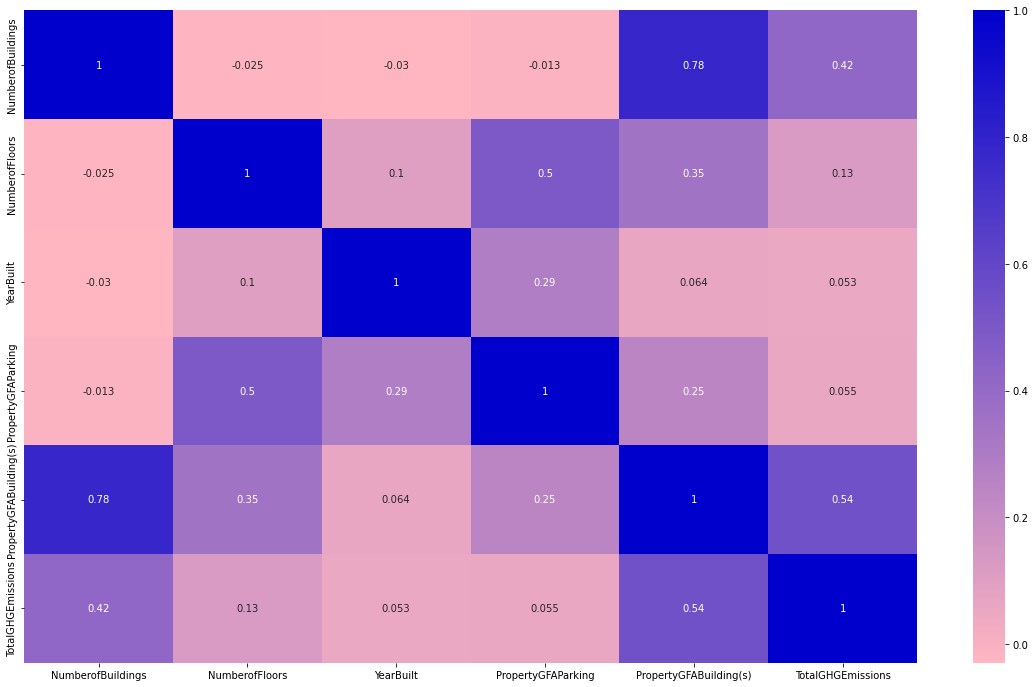

In [23]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(data_modelisation_em.corr(), annot=True, cmap=cmap)
plt.show()


### modélisation de la prédiction emission de CO2 

In [24]:
data_modelisation_em.columns

Index(['NumberofBuildings', 'NumberofFloors', 'PrimaryPropertyType',
       'YearBuilt', 'PropertyGFAParking', 'PropertyGFABuilding(s)',
       'TotalGHGEmissions'],
      dtype='object')

In [25]:
data_modelisation_em.head()

,NumberofBuildings,NumberofFloors,PrimaryPropertyType,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),TotalGHGEmissions
0,1.0,12.0,Hotel,1927.0,0.0,88434.0,249.98
1,1.0,11.0,Hotel,1996.0,15064.0,88502.0,295.86
2,1.0,41.0,Hotel,1969.0,196718.0,759392.0,2089.28
3,1.0,10.0,Hotel,1926.0,0.0,61320.0,286.43
4,1.0,18.0,Hotel,1980.0,62000.0,113580.0,505.01


In [26]:
data_modelisation_em.isna().sum()

NumberofBuildings         0
NumberofFloors            0
PrimaryPropertyType       0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
TotalGHGEmissions         0
dtype: int64

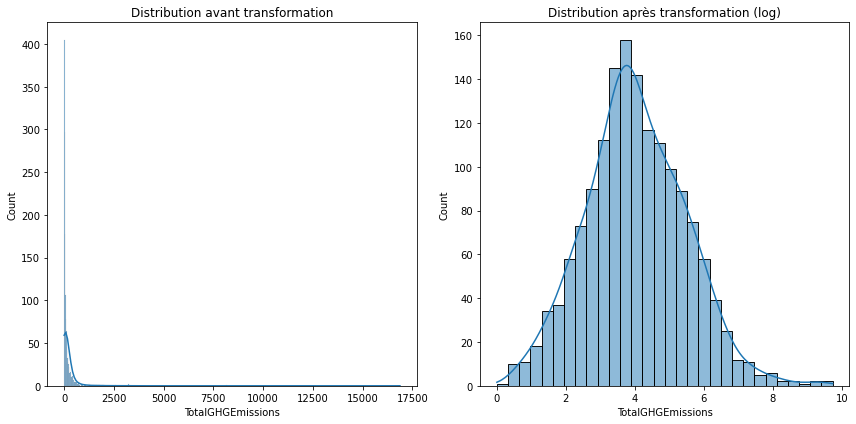

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_em["TotalGHGEmissions"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_emissions_log = np.log1p(data_modelisation_em["TotalGHGEmissions"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_emissions_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_em_modified = data_modelisation_em.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_em_modified["TotalGHGEmissions"] = np.log1p(data_modelisation_em_modified["TotalGHGEmissions"])

data_modelisation_em = data_modelisation_em_modified



In [28]:
def has_negative_values(df):
    numeric_df = df.select_dtypes(include=[np.number])
    return numeric_df.lt(0).any().any()

if has_negative_values(data_modelisation_em):
    print("Le dataframe contient des valeurs négatives.")
else:
    print("Le dataframe ne contient pas de valeurs négatives.")


Le dataframe ne contient pas de valeurs négatives.


In [29]:
data_modelisation_em.columns

Index(['NumberofBuildings', 'NumberofFloors', 'PrimaryPropertyType',
       'YearBuilt', 'PropertyGFAParking', 'PropertyGFABuilding(s)',
       'TotalGHGEmissions'],
      dtype='object')

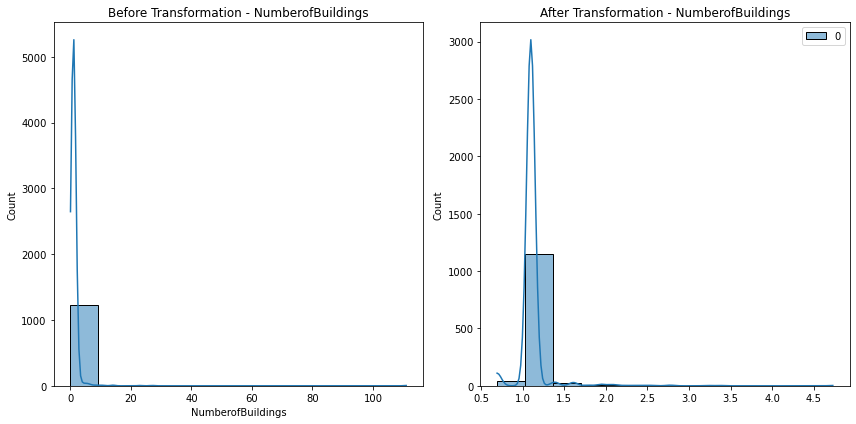

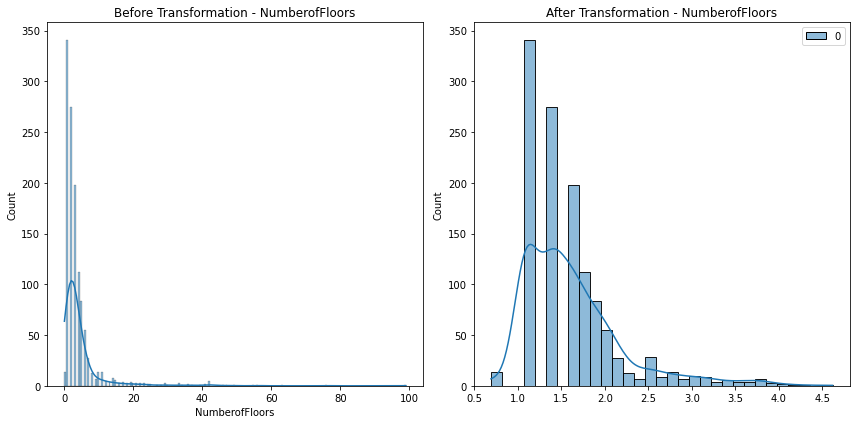

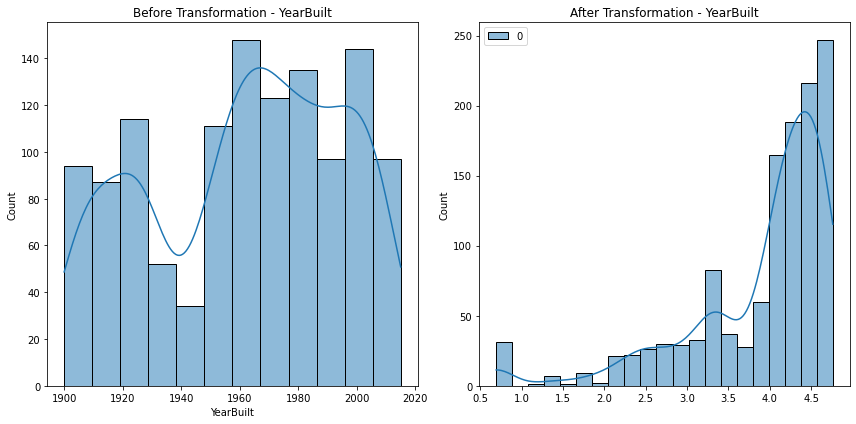

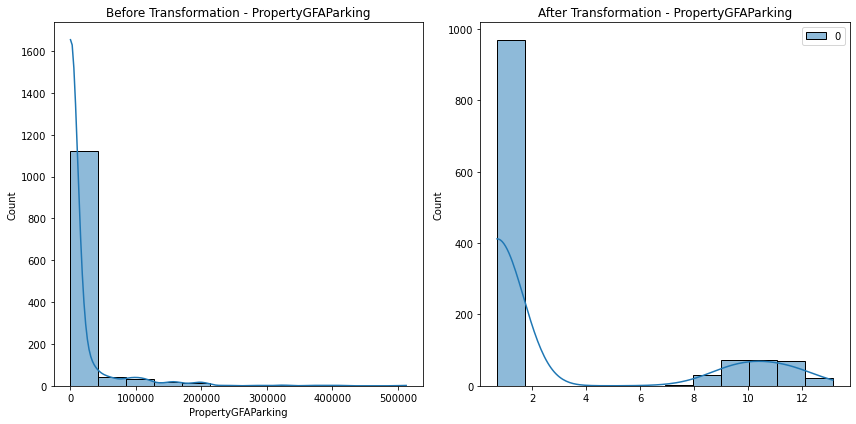

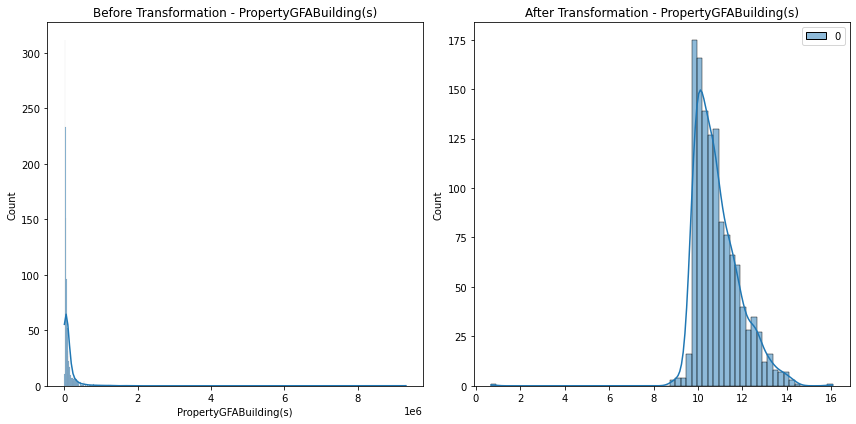

Ridge - Best parameters:  {'regressor__alpha': 1.0, 'regressor__tol': 0.01}
Ridge - Best cross-validation score (R2):  0.45981441796152644
Lasso - Best parameters:  {'regressor__alpha': 0.001, 'regressor__tol': 0.01}
Lasso - Best cross-validation score (R2):  0.4538194761537455
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 8, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}
RandomForestRegressor - Best cross-validation score (R2):  0.49501334686882253
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
GradientBoostingRegressor - Best cross-validation score (R2):  0.5278777421040378


In [30]:
grid_search_ridge_before_fe_em, grid_search_lasso_before_fe_em, grid_search_rf_before_fe_em, grid_search_gbr_before_fe_em, X_train_before_fe_em, X_test_before_fe_em, y_train_before_fe_em, y_test_before_fe_em = run_modeling_pipeline(df=data_modelisation_em, target_col="TotalGHGEmissions", show_graphs=True, random_seed=42, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[0.01], ridge_max_iter=10000, lasso_max_iter=10000)



In [194]:
best_score_ridge_before_fe_em = grid_search_ridge_before_fe_em.best_score_
best_score_lasso_before_fe_em = grid_search_lasso_before_fe_em.best_score_
best_score_rf_before_fe_em = grid_search_rf_before_fe_em.best_score_
best_score_gbr_before_fe_em = grid_search_gbr_before_fe_em.best_score_

best_params_ridge_before_fe_em = grid_search_ridge_before_fe_em.best_params_
best_params_lasso_before_fe_em = grid_search_lasso_before_fe_em.best_params_
best_params_rf_before_fe_em = grid_search_rf_before_fe_em.best_params_
best_params_gbr_before_fe_em = grid_search_gbr_before_fe_em.best_params_




<div style="background-color:orange; color:dark;"> 
    <strong>évaluer les performances de chaque modèle sur l'ensemble d'entraînement </strong>
    <br>Calcul du score R2 et l'erreur quadratique moyenne (MSE) sur l'ensemble d'entraînement pour chaque modèle, et les comparer aux scores sur l'ensemble de test<br>
</div>


le score R2 donne une indication de la proportion de variance expliquée par le modèle, le MSE quantifie l'erreur résiduelle en termes de distance au carré des prédictions du modèle par rapport aux valeurs réelles.

# 🔴 RESULTS 1 avant feature engineering -- émission

In [195]:
summary_before_fe_em = display_summary([grid_search_ridge_before_fe_em, grid_search_lasso_before_fe_em, grid_search_rf_before_fe_em, grid_search_gbr_before_fe_em], 
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_before_fe_em, y_train_before_fe_em, X_test_before_fe_em, y_test_before_fe_em)
summary_before_fe_em

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 1.0, 'regressor__tol': 0.01}",0.459814,0.515666,0.523940,1.020606,0.997603,1.010250,0.998801,0.788018,0.796131
1,Lasso,"{'regressor__alpha': 0.001, 'regressor__tol': 0.01}",0.453819,0.524196,0.558883,1.002632,0.924379,1.001315,0.961446,0.777629,0.769762
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 8, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}",0.495013,0.691514,0.525922,0.650053,0.993449,0.806259,0.996719,0.627087,0.791987
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}",0.527878,0.645679,0.552502,0.746639,0.937750,0.864083,0.968375,0.677088,0.772369


Le modèle de Ridge Regression semble avoir les performances les moins bonnes, car il a les erreurs les plus élevées sur les données d'entraînement et de test.

Le modèle de Lasso Regression fait légèrement mieux que le modèle de Ridge Regression.

Le modèle de Random Forest Regression semble faire le mieux sur les données d'entraînement, avec les erreurs les plus faibles. Cependant, sur les données de test, il a les deuxièmes erreurs les plus élevées après la Ridge Regression, ce qui pourrait indiquer un surapprentissage sur les données d'entraînement.

Le modèle de Gradient Boosting Regression a des performances moyennes sur les données d'entraînement, mais fait un peu mieux que le modèle de Random Forest sur les données de test.

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Lorsqu'on compare les scores R2 de l'ensemble d'entraînement et de l'ensemble de validation, il semble que les modèles de RandomForest et GradientBoosting pourraient être en train de surajuster les données. Le surajustement se produit lorsque le modèle apprend trop bien les détails et le bruit des données d'entraînement, au point où cela nuit à la performance du modèle sur de nouvelles données. C'est ce que l'on peut déduire ici car il y a une grande différence entre les scores R2 d'entraînement et de validation pour ces deux modèles.
    <br><br>
     le modèle RandomForestRegressor a le meilleur score R2 sur l'ensemble d'entraînement, mais le pire score R2 sur l'ensemble de test. Cela pourrait indiquer que ce modèle est en surapprentissage sur l'ensemble d'entraînement et ne généralise pas bien à de nouvelles données.
<br><br>
les modèles Ridge et Lasso semblent sous-ajuster les données. Le sous-ajustement se produit lorsque le modèle ne peut pas apprendre les tendances sous-jacentes des données. Les faibles scores R2 à la fois sur l'ensemble d'entraînement et sur l'ensemble de validation montrent que ces modèles n'ont pas été capables de capturer la complexité des données.

</p> 

MSE (Mean Squared Error) : L'erreur quadratique moyenne est calculée comme la moyenne des carrés des écarts entre les valeurs prédites et les valeurs réelles. Elle mesure la moyenne des erreurs au carré, ce qui donne plus de poids aux erreurs importantes. Le MSE est sensible aux valeurs aberrantes car il utilise les carrés des écarts.

RMSE (Root Mean Squared Error) : La racine carrée de l'erreur quadratique moyenne est simplement la racine carrée du MSE. Elle représente une mesure de l'erreur moyenne entre les valeurs prédites et les valeurs réelles, exprimée dans la même unité que la variable cible. Le RMSE est largement utilisé car il est facilement interprétable et donne une estimation de l'erreur moyenne.

MAE (Mean Absolute Error) : L'erreur absolue moyenne est calculée comme la moyenne des valeurs absolues des écarts entre les valeurs prédites et les valeurs réelles. Contrairement au MSE et au RMSE, le MAE ne tient pas compte des carrés des erreurs. Il mesure directement l'erreur moyenne, indépendamment de sa direction, et est plus robuste aux valeurs aberrantes.

#### features importance

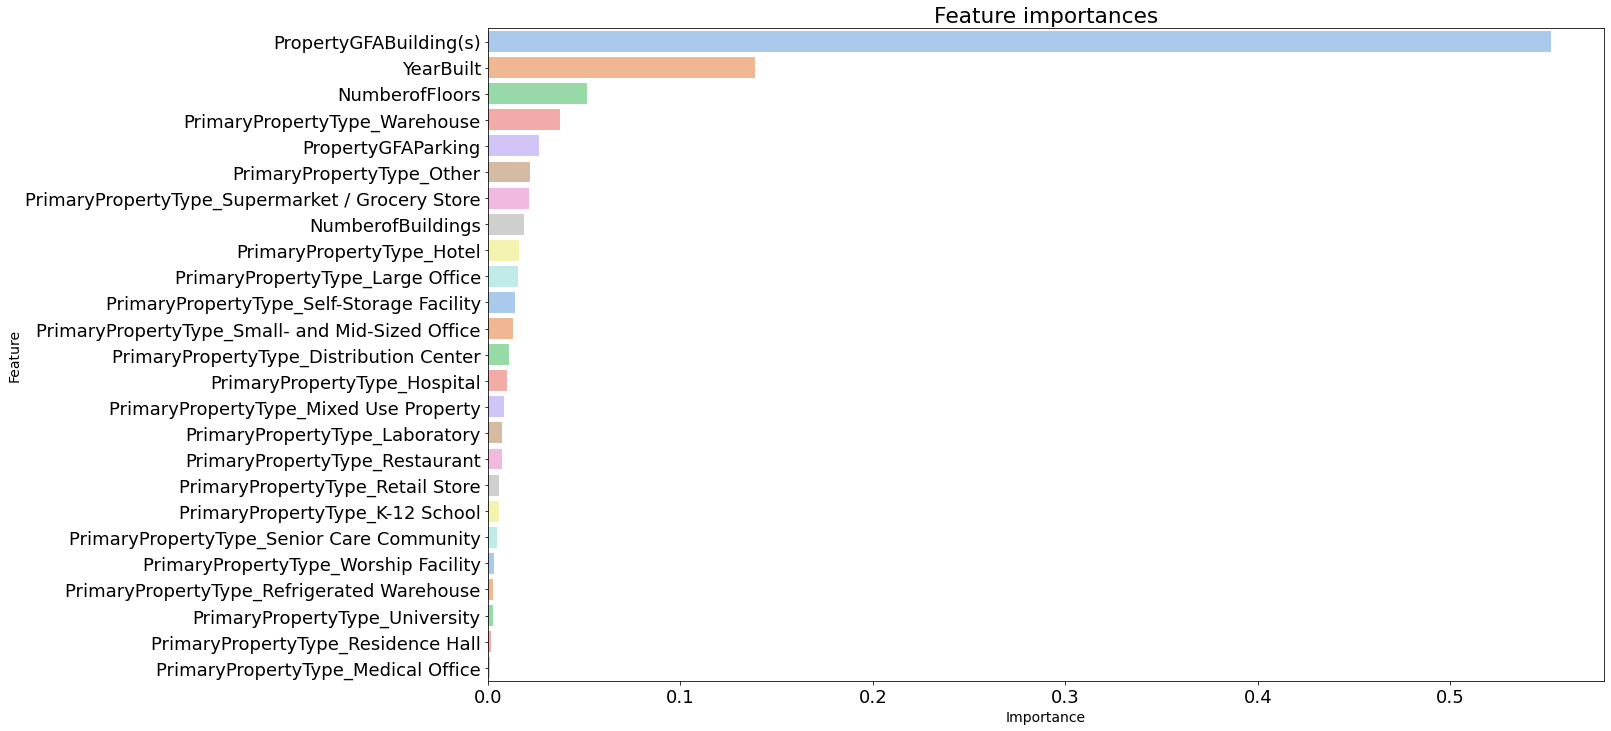

In [90]:
feature_importance_before_fe_em =feature_importance(df=data_modelisation_em, target_col="TotalGHGEmissions")
feature_importance_before_fe_em

 plus une caractéristique est importante, plus elle a contribué à la prédiction du modèle

# Feature engineering energy use type

## add energy type and compliance status columns

In [91]:
df_feature1 = data_clean[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","SteamUse(kBtu)","NaturalGas(kBtu)","Electricity(kBtu)","TotalGHGEmissions","SiteEnergyUse(kBtu)"]]



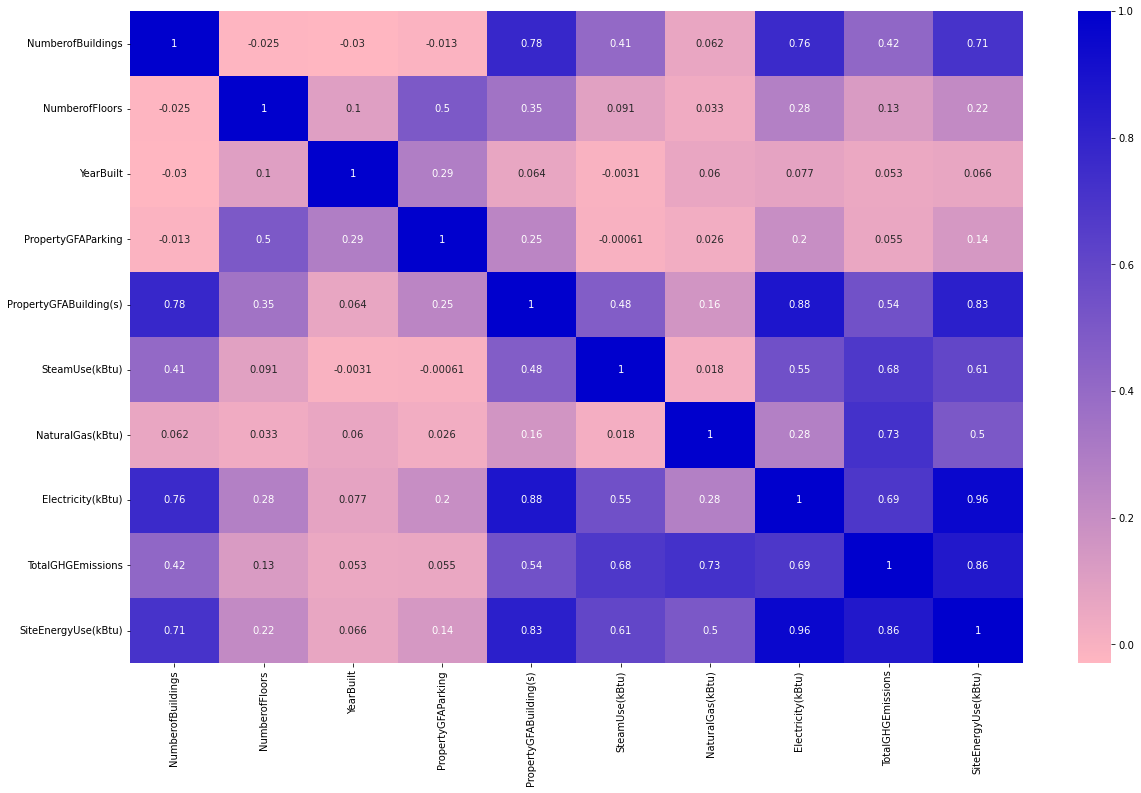

In [92]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(df_feature1.corr(), annot=True, cmap=cmap)
plt.show()


In [93]:
df_feature1.isna().sum()

NumberofBuildings         0
NumberofFloors            0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
PrimaryPropertyType       0
SteamUse(kBtu)            0
NaturalGas(kBtu)          0
Electricity(kBtu)         1
TotalGHGEmissions         1
SiteEnergyUse(kBtu)       0
dtype: int64

In [94]:
qualitative_cols = df_feature1.select_dtypes(include='object').columns.tolist()

for col in qualitative_cols:
    unique_values = data[col].unique()
    print("\n",col, ": valeurs uniques", len(unique_values),"\n", unique_values)


 PrimaryPropertyType : valeurs uniques 24 
 ['Hotel' 'Other' 'Mid-Rise Multifamily' 'Mixed Use Property' 'K-12 School'
 'University' 'Small- and Mid-Sized Office' 'Self-Storage Facility'
 'Warehouse' 'Large Office' 'Senior Care Community' 'Medical Office'
 'Retail Store' 'Hospital' 'Residence Hall' 'Distribution Center'
 'Worship Facility' 'Low-Rise Multifamily' 'Supermarket / Grocery Store'
 'Laboratory' 'Refrigerated Warehouse' 'Restaurant'
 'High-Rise Multifamily' 'Office']


In [95]:
# Créer des colonnes pour les types d'énergie
df_feature1['HasElectricity'] = df_feature1['Electricity(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1['HasNaturalGas'] = df_feature1['NaturalGas(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1['HasSteam'] = df_feature1['SteamUse(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,SteamUse(kBtu),NaturalGas(kBtu),Electricity(kBtu),TotalGHGEmissions,SiteEnergyUse(kBtu),HasElectricity,HasNaturalGas,HasSteam
0,1.0,12,1927,0,88434,Hotel,2003882.00,1.276453e+06,3.946027e+06,249.98,7.226362e+06,oui,oui,oui
1,1.0,11,1996,15064,88502,Hotel,0.00,5.145082e+06,3.242851e+06,295.86,8.387933e+06,oui,oui,non
2,1.0,41,1969,196718,759392,Hotel,21566554.00,1.493800e+06,4.952666e+07,2089.28,7.258702e+07,oui,oui,oui
3,1.0,10,1926,0,61320,Hotel,2214446.25,1.811213e+06,2.768924e+06,286.43,6.794584e+06,oui,oui,oui
4,1.0,18,1980,62000,113580,Hotel,0.00,8.803998e+06,5.368607e+06,505.01,1.417261e+07,oui,oui,non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3370,1.0,1,1982,0,18261,Other,0.00,2.997200e+05,6.323620e+05,20.33,9.320821e+05,oui,oui,non
3372,1.0,1,2004,0,16000,Other,0.00,5.537300e+05,3.965461e+05,32.17,9.502762e+05,oui,oui,non
3373,1.0,1,1974,0,13157,Other,0.00,3.973739e+06,1.792159e+06,223.54,5.765898e+06,oui,oui,non
3374,1.0,1,1989,0,14101,Mixed Use Property,0.00,3.706010e+05,3.488702e+05,22.11,7.194712e+05,oui,oui,non


In [96]:
df_feature1 = df_feature1.drop(['Electricity(kBtu)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)'], axis=1)

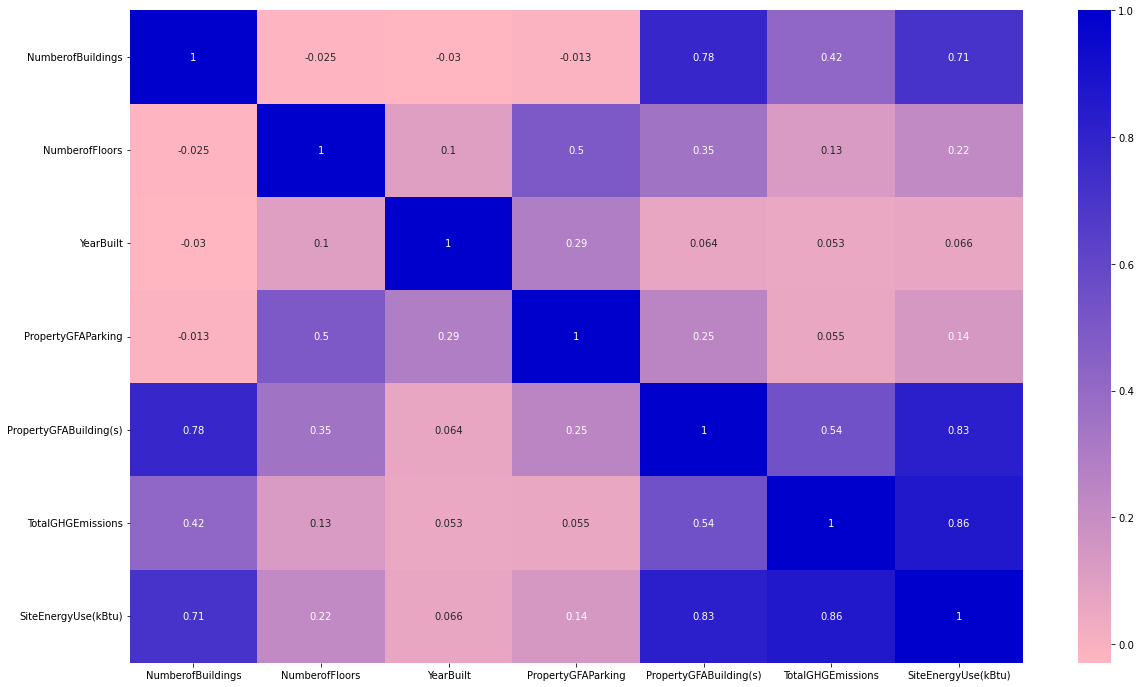

In [97]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(df_feature1.corr(), annot=True, cmap=cmap)
plt.show()

In [98]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_clean_before_imputation2 = df_feature1
data_imputed2 = impute_and_normalize_data(data_clean_before_imputation2, target_cols)
data_imputed2

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,HasElectricity,HasNaturalGas,HasSteam,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,oui,oui,oui,249.98,7.226362e+06
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,oui,oui,non,295.86,8.387933e+06
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,oui,oui,oui,2089.28,7.258702e+07
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,oui,oui,oui,286.43,6.794584e+06
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,oui,oui,non,505.01,1.417261e+07
...,...,...,...,...,...,...,...,...,...,...,...
1541,1.0,1.0,1982.0,0.0,18261.0,Other,oui,oui,non,20.33,9.320821e+05
1542,1.0,1.0,2004.0,0.0,16000.0,Other,oui,oui,non,32.17,9.502762e+05
1543,1.0,1.0,1974.0,0.0,13157.0,Other,oui,oui,non,223.54,5.765898e+06
1544,1.0,1.0,1989.0,0.0,14101.0,Mixed Use Property,oui,oui,non,22.11,7.194712e+05


In [99]:
data_imputed2.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1545 entries, 0 to 1545
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NumberofBuildings       1545 non-null   float64
 1   NumberofFloors          1545 non-null   float64
 2   YearBuilt               1545 non-null   float64
 3   PropertyGFAParking      1545 non-null   float64
 4   PropertyGFABuilding(s)  1545 non-null   float64
 5   PrimaryPropertyType     1545 non-null   object 
 6   HasElectricity          1545 non-null   object 
 7   HasNaturalGas           1545 non-null   object 
 8   HasSteam                1545 non-null   object 
 9   TotalGHGEmissions       1545 non-null   float64
 10  SiteEnergyUse(kBtu)     1545 non-null   float64
dtypes: float64(7), object(4)
memory usage: 144.8+ KB


In [100]:
data_modelisation_em2 = data_imputed2[["NumberofBuildings", "NumberofFloors", "PrimaryPropertyType","YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", 'HasElectricity','HasNaturalGas','HasSteam','TotalGHGEmissions']]
data_modelisation_conso2 = data_imputed2[["NumberofBuildings", "NumberofFloors", "PrimaryPropertyType","YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", 'HasElectricity','HasNaturalGas','HasSteam', 'SiteEnergyUse(kBtu)']]

### modélisation de la prédiction emission de CO2

In [101]:
def has_negative_values(df):
    numeric_df = df.select_dtypes(include=[np.number])
    return numeric_df.lt(0).any().any()

if has_negative_values(data_modelisation_em2):
    print("Le dataframe contient des valeurs négatives.")
else:
    print("Le dataframe ne contient pas de valeurs négatives.")


Le dataframe ne contient pas de valeurs négatives.


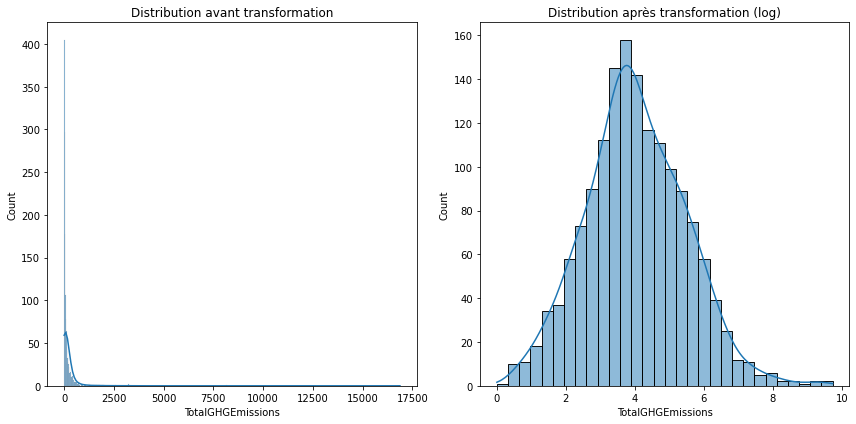

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_em2["TotalGHGEmissions"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_emissions2_log = np.log1p(data_modelisation_em2["TotalGHGEmissions"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_emissions2_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_em2_modified = data_modelisation_em2.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_em2_modified["TotalGHGEmissions"] = np.log1p(data_modelisation_em2_modified["TotalGHGEmissions"])

data_modelisation_em2 = data_modelisation_em2_modified


In [142]:
grid_search_ridge_fe_em, grid_search_lasso_fe_em, grid_search_rf_fe_em, grid_search_gbr_fe_em, X_train_fe_em, X_test_fe_em, y_train_fe_em, y_test_fe_em = run_modeling_pipeline(df=data_modelisation_em2, target_col="TotalGHGEmissions", show_graphs=False, random_seed=22, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[1e-3, 1e-4, 1e-5])




Ridge - Best parameters:  {'regressor__alpha': 1.0, 'regressor__tol': 1e-05}
Ridge - Best cross-validation score (R2):  0.5747384204987721
Lasso - Best parameters:  {'regressor__alpha': 0.001, 'regressor__tol': 1e-05}
Lasso - Best cross-validation score (R2):  0.5726406723094064
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}
RandomForestRegressor - Best cross-validation score (R2):  0.6677119115717796
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
GradientBoostingRegressor - Best cross-validation score (R2):  0.6775877541520468


In [191]:
best_score_ridge_fe_em = grid_search_ridge_fe_em.best_score_
best_score_lasso_fe_em = grid_search_lasso_fe_em.best_score_
best_score_rf_fe_em = grid_search_rf_fe_em.best_score_
best_score_gbr_fe_em = grid_search_gbr_fe_em.best_score_

best_params_ridge_fe_em = grid_search_ridge_fe_em.best_params_
best_params_lasso_fe_em = grid_search_lasso_fe_em.best_params_
best_params_rf_fe_em = grid_search_rf_fe_em.best_params_
best_params_gbr_fe_em = grid_search_gbr_fe_em.best_params_




<div style="background-color:orange; color:dark;"> 
    <strong>évaluer les performances de chaque modèle sur l'ensemble d'entraînement </strong>
    <br>Calcul du score R2 et l'erreur quadratique moyenne (MSE) sur l'ensemble d'entraînement pour chaque modèle, et les comparer aux scores sur l'ensemble de tesat<br>
</div>


# 🔴RESULTS 2 après feature engineering 1 -- émissions

In [192]:
summary_fe_em = display_summary([grid_search_ridge_fe_em, grid_search_lasso_fe_em, grid_search_rf_fe_em, grid_search_gbr_fe_em],
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_fe_em, y_train_fe_em, X_test_fe_em, y_test_fe_em)
summary_fe_em

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 1.0, 'regressor__tol': 1e-05}",0.574738,0.649325,0.639964,0.034687,0.036432,0.186244,0.190871,0.141940,0.147933
1,Lasso,"{'regressor__alpha': 0.001, 'regressor__tol': 1e-05}",0.572641,0.638673,0.631743,0.035740,0.037264,0.189051,0.193038,0.142363,0.149641
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}",0.667712,0.865823,0.689997,0.013272,0.031369,0.115204,0.177113,0.086981,0.133658
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}",0.677588,0.781775,0.696856,0.021586,0.030675,0.146920,0.175143,0.110320,0.130941


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Lorsqu'on compare les scores R2 de l'ensemble d'entraînement et de l'ensemble de validation, il semble que les modèles de RandomForest et GradientBoosting pourraient être en train de surajuster les données. Le surajustement se produit lorsque le modèle apprend trop bien les détails et le bruit des données d'entraînement, au point où cela nuit à la performance du modèle sur de nouvelles données. C'est ce que l'on peut déduire ici car il y a une grande différence entre les scores R2 d'entraînement et de validation pour ces deux modèles.
<br><br>
les modèles Ridge et Lasso semblent sous-ajuster les données. Le sous-ajustement se produit lorsque le modèle ne peut pas apprendre les tendances sous-jacentes des données. Les faibles scores R2 à la fois sur l'ensemble d'entraînement et sur l'ensemble de validation montrent que ces modèles n'ont pas été capables de capturer la complexité des données.

</p> 

#### features importance

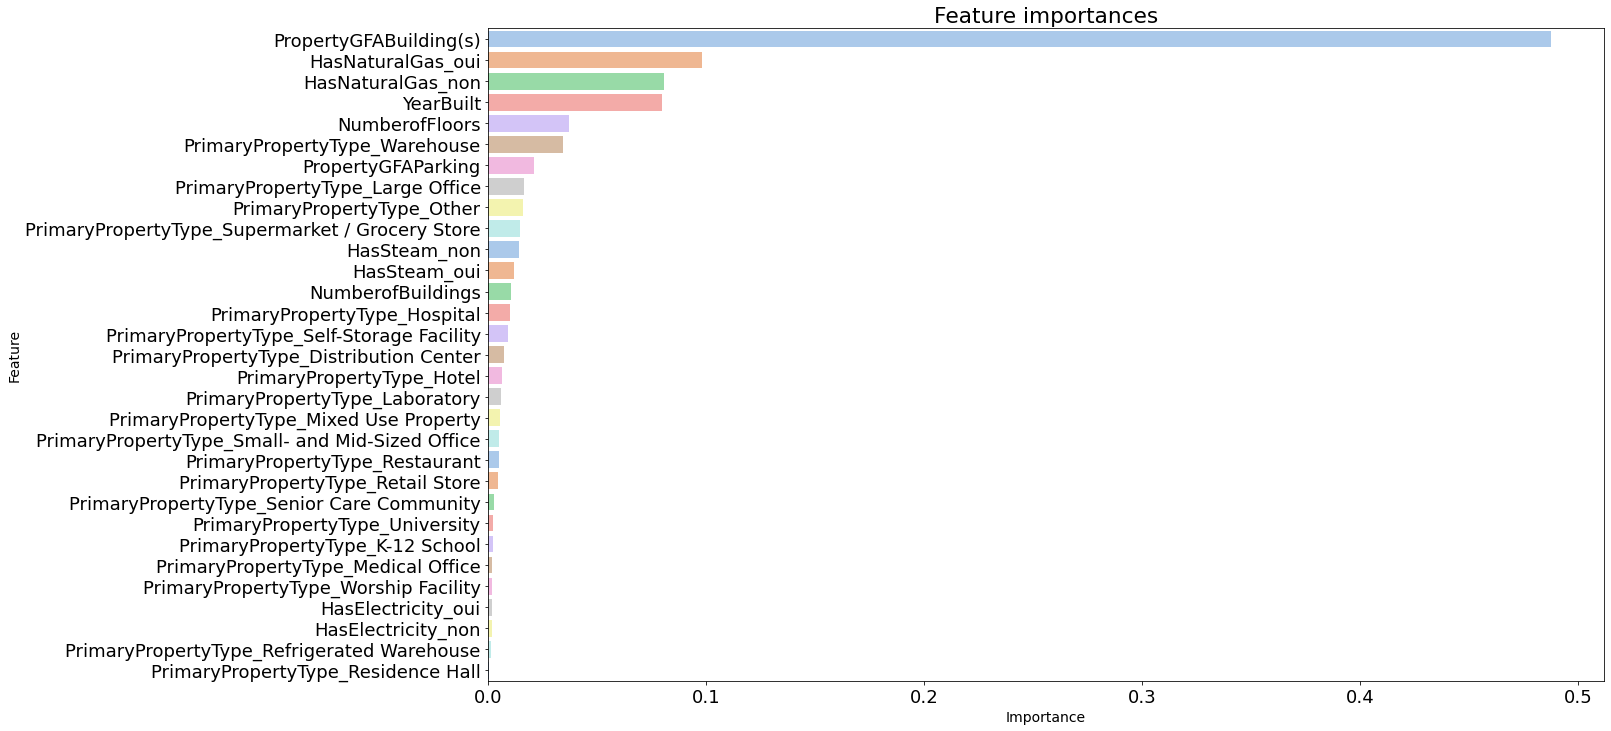

In [111]:
feature_importance(df=data_modelisation_em2, target_col="TotalGHGEmissions")

# Feature engineering avec localisation

In [167]:
data_clean_before_imputation3 = data_clean[["NumberofBuildings", "Latitude","Longitude","NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","SiteEnergyUse(kBtu)","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)"]]
data_clean_before_imputation3.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1546 entries, 0 to 3375
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NumberofBuildings       1546 non-null   float64
 1   Latitude                1546 non-null   float64
 2   Longitude               1546 non-null   float64
 3   NumberofFloors          1546 non-null   int64  
 4   YearBuilt               1546 non-null   int64  
 5   PropertyGFAParking      1546 non-null   int64  
 6   PropertyGFABuilding(s)  1546 non-null   int64  
 7   PrimaryPropertyType     1546 non-null   object 
 8   TotalGHGEmissions       1545 non-null   float64
 9   SiteEnergyUse(kBtu)     1546 non-null   float64
 10  Electricity(kBtu)       1545 non-null   float64
 11  NaturalGas(kBtu)        1546 non-null   float64
 12  SteamUse(kBtu)          1546 non-null   float64
dtypes: float64(8), int64(4), object(1)
memory usage: 169.1+ KB


<div style="background-color:orange; color:dark;"> calcule la distance de chaque bâtiment par rapport au point le plus pollué. Cette distance est ajoutée au DataFrame sous la colonne Distance_Center.<br>
    calcule de la distance de chaque point de données à ce centre-ville supposé. C'est une approche intéressante de l'ingénierie des caractéristiques.
</div>

In [168]:
target_cols = ['TotalGHGEmissions']
data_imputed3 = impute_and_normalize_data(data_clean_before_imputation3, target_cols)

In [169]:
!pip install folium

In [170]:
import folium
from folium.plugins import HeatMap

def find_city_center(df):
    # Création d'une carte avec une heatmap des émissions de gaz à effet de serre (TotalGHGEmissions)
    map_total = folium.Map(location=[df["Latitude"].mean(), df["Longitude"].mean()], zoom_start=11)
    HeatMap(data=df[["Latitude", "Longitude", "TotalGHGEmissions"]], radius=10).add_to(map_total)
    map_total.save("map_total.html")

    # Trouver la localisation la plus polluée dans le DataFrame
    lat_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Latitude"]
    lon_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Longitude"]
    print(f"La localisation la plus polluée se trouve à (latitude, longitude) = ({lat_center:.4f}, {lon_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur la localisation la plus polluée
    map_center = folium.Map(location=[lat_center, lon_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_center)
    map_center.save("map_center.html")

    # Calcul de la distance par rapport à la localisation la plus polluée
    df["Distance_Center"] = np.sqrt((df["Latitude"] - lat_center)**2 + (df["Longitude"] - lon_center)**2)

    # Interprétation de la localisation la plus polluée comme le centre-ville
    df["Distance_CityCenter"] = df["Distance_Center"].apply(lambda x: np.abs(x - df["Distance_Center"].mean()))
    lat_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Latitude"]
    lon_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Longitude"]
    print(f"Le centre-ville est interprété comme la localisation à (latitude, longitude) = ({lat_city_center:.4f}, {lon_city_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur le centre-ville
    map_city_center = folium.Map(location=[lat_city_center, lon_city_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_city_center)
    map_city_center.save("map_city_center.html")


In [171]:
find_city_center(data_imputed3)

La localisation la plus polluée se trouve à (latitude, longitude) = (47.5349, -122.3179)
Le centre-ville est interprété comme la localisation à (latitude, longitude) = (47.6164, -122.3509)


In [172]:
data_modelisation_em3.head()

,Distance_CityCenter,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,HasElectricity,HasNaturalGas,HasSteam
0,0.007980,1.0,12.0,1927.0,0.0,88434.0,Hotel,5.525373,oui,oui,oui
1,0.007955,1.0,11.0,1996.0,15064.0,88502.0,Hotel,5.693261,oui,oui,non
2,0.006278,1.0,41.0,1969.0,196718.0,759392.0,Hotel,7.645053,oui,oui,oui
3,0.006442,1.0,10.0,1926.0,0.0,61320.0,Hotel,5.660979,oui,oui,oui
4,0.005831,1.0,18.0,1980.0,62000.0,113580.0,Hotel,6.226556,oui,oui,non


In [173]:
import folium

# Créez une carte centrée sur le centre-ville
map = folium.Map(location=[47.6164, -122.3509], zoom_start=13)

# Ajoutez chaque point à la carte
for idx, row in data.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.6
    ).add_to(map)

# Affichez la carte
map


In [174]:
data_modelisation_em3 = data_imputed3[["Distance_CityCenter","NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)",'TotalGHGEmissions']]


In [175]:
# Créer des colonnes pour les types d'énergie
data_modelisation_em3['HasElectricity'] = data_modelisation_em3['Electricity(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_em3['HasNaturalGas'] = data_modelisation_em3['NaturalGas(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_em3['HasSteam'] = data_modelisation_em3['SteamUse(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_em3 = data_modelisation_em3.drop(['Electricity(kBtu)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)'], axis=1)



A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


### modélisation de la prédiction emission de CO2

In [176]:
data_imputed3

,NumberofBuildings,Latitude,Longitude,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),SiteEnergyUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),SteamUse(kBtu),PrimaryPropertyType,TotalGHGEmissions,Distance_Center,Distance_CityCenter
0,1.0,47.61220,-122.33799,12.0,1927.0,0.0,88434.0,7.226362e+06,3.946027e+06,1.276453e+06,2003882.00,Hotel,249.98,0.079844,0.007980
1,1.0,47.61317,-122.33393,11.0,1996.0,15064.0,88502.0,8.387933e+06,3.242851e+06,5.145082e+06,0.00,Hotel,295.86,0.079869,0.007955
2,1.0,47.61393,-122.33810,41.0,1969.0,196718.0,759392.0,7.258702e+07,4.952666e+07,1.493800e+06,21566554.00,Hotel,2089.28,0.081547,0.006278
3,1.0,47.61412,-122.33664,10.0,1926.0,0.0,61320.0,6.794584e+06,2.768924e+06,1.811213e+06,2214446.25,Hotel,286.43,0.081382,0.006442
4,1.0,47.61375,-122.34047,18.0,1980.0,62000.0,113580.0,1.417261e+07,5.368607e+06,8.803998e+06,0.00,Hotel,505.01,0.081993,0.005831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1541,1.0,47.54067,-122.37441,1.0,1982.0,0.0,18261.0,9.320821e+05,6.323620e+05,2.997200e+05,0.00,Other,20.33,0.056821,0.031004
1542,1.0,47.59625,-122.32283,1.0,2004.0,0.0,16000.0,9.502762e+05,3.965461e+05,5.537300e+05,0.00,Other,32.17,0.061519,0.026305
1543,1.0,47.63644,-122.35784,1.0,1974.0,0.0,13157.0,5.765898e+06,1.792159e+06,3.973739e+06,0.00,Other,223.54,0.109092,0.021268
1544,1.0,47.52832,-122.32431,1.0,1989.0,0.0,14101.0,7.194712e+05,3.488702e+05,3.706010e+05,0.00,Mixed Use Property,22.11,0.009222,0.078603


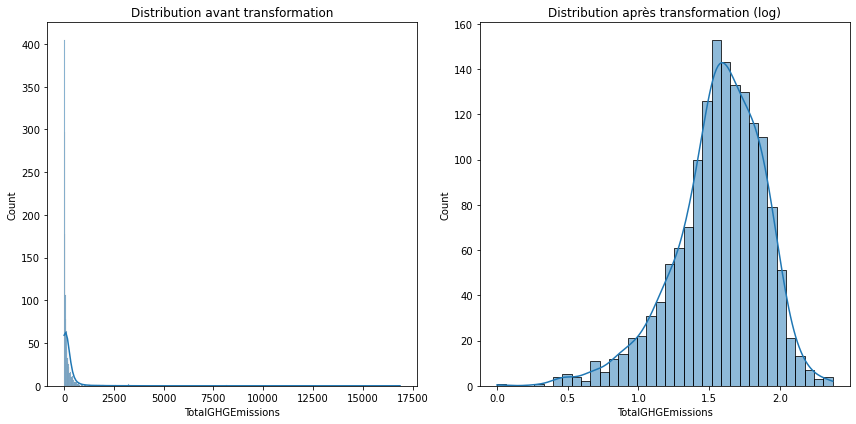

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_em3["TotalGHGEmissions"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_emissions3_log = np.log1p(data_modelisation_em3["TotalGHGEmissions"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_emissions_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_em3_modified = data_modelisation_em3.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_em3_modified["TotalGHGEmissions"] = np.log1p(data_modelisation_em3_modified["TotalGHGEmissions"])

data_modelisation_em3 = data_modelisation_em3_modified



In [161]:
data_modelisation_em3

,Distance_CityCenter,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,HasElectricity,HasNaturalGas,HasSteam
0,0.007980,1.0,12.0,1927.0,0.0,88434.0,Hotel,5.525373,oui,oui,oui
1,0.007955,1.0,11.0,1996.0,15064.0,88502.0,Hotel,5.693261,oui,oui,non
2,0.006278,1.0,41.0,1969.0,196718.0,759392.0,Hotel,7.645053,oui,oui,oui
3,0.006442,1.0,10.0,1926.0,0.0,61320.0,Hotel,5.660979,oui,oui,oui
4,0.005831,1.0,18.0,1980.0,62000.0,113580.0,Hotel,6.226556,oui,oui,non
...,...,...,...,...,...,...,...,...,...,...,...
1541,0.031004,1.0,1.0,1982.0,0.0,18261.0,Other,3.060115,oui,oui,non
1542,0.026305,1.0,1.0,2004.0,0.0,16000.0,Other,3.501646,oui,oui,non
1543,0.021268,1.0,1.0,1974.0,0.0,13157.0,Other,5.414054,oui,oui,non
1544,0.078603,1.0,1.0,1989.0,0.0,14101.0,Mixed Use Property,3.140265,oui,oui,non


In [162]:
def has_negative_values(df):
    numeric_df = df.select_dtypes(include=[np.number])
    return numeric_df.lt(0).any().any()

if has_negative_values(data_modelisation_em3):
    print("Le dataframe contient des valeurs négatives.")
else:
    print("Le dataframe ne contient pas de valeurs négatives.")

Le dataframe ne contient pas de valeurs négatives.


In [183]:
grid_search_ridge_fe2_em, grid_search_lasso_fe2_em, grid_search_rf_fe2_em, grid_search_gbr_fe2_em, X_train_fe2_em, X_test_fe2_em, y_train_fe2_em, y_test_fe2_em = run_modeling_pipeline(df=data_modelisation_em3, target_col="TotalGHGEmissions", show_graphs=False, random_seed=38, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[1e-3, 1e-4, 1e-5])



Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.867e+06, tolerance: 4.875e+05
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.956e+06, tolerance: 3.051e+05
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.686e+06, tolerance: 3.395e+05
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.932e+06, tolerance: 4.400e+05
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.532e+07, tolerance: 4.695e+05
Objective did n

Ridge - Best parameters:  {'regressor__alpha': 10.0, 'regressor__tol': 0.001}
Ridge - Best cross-validation score (R2):  0.32054609328679007
Lasso - Best parameters:  {'regressor__alpha': 0.1, 'regressor__tol': 0.001}
Lasso - Best cross-validation score (R2):  -0.028703457031147784
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 8, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}
RandomForestRegressor - Best cross-validation score (R2):  0.5238555052839198
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3, 'regressor__n_estimators': 100}
GradientBoostingRegressor - Best cross-validation score (R2):  0.6905856575913629


In [179]:
best_score_ridge_fe2_em = grid_search_ridge_fe2_em.best_score_
best_score_lasso_fe2_em = grid_search_lasso_fe2_em.best_score_
best_score_rf_fe2_em = grid_search_rf_fe2_em.best_score_
best_score_gbr_fe2_em = grid_search_gbr_fe2_em.best_score_

best_params_ridge_fe2_em = grid_search_ridge_fe2_em.best_params_
best_params_lasso_fe2_em = grid_search_lasso_fe2_em.best_params_
best_params_rf_fe2_em = grid_search_rf_fe2_em.best_params_
best_params_gbr_fe2_em = grid_search_gbr_fe2_em.best_params_




<div style="background-color:orange; color:dark;"> 
    <strong>évaluer les performances de chaque modèle sur l'ensemble d'entraînement </strong>
    <br>Calcul du score R2 et l'erreur quadratique moyenne (MSE) sur l'ensemble d'entraînement pour chaque modèle, et les comparer aux scores sur l'ensemble de tesat<br>
</div>


# 🔴RESULTS 3 après feature engineering 2 -- émissions

In [185]:
summary = display_summary([grid_search_ridge_fe2_em, grid_search_lasso_fe2_em, grid_search_rf_fe2_em, grid_search_gbr_fe2_em], 
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_fe2_em, y_train_fe2_em, X_test_fe2_em, y_test_fe2_em)
summary

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 10.0, 'regressor__tol': 0.001}",0.320546,0.501961,0.127056,205688.149898,1208460.637092,453.528555,1099.300067,151.617671,210.846713
1,Lasso,"{'regressor__alpha': 0.1, 'regressor__tol': 0.001}",-0.028703,0.623868,0.164283,155341.036923,1156925.286009,394.133273,1075.604614,158.114135,228.234407
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 8, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}",0.523856,0.951161,0.215692,20170.492321,1085757.702020,142.022858,1041.996978,73.950883,186.553773
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3, 'regressor__n_estimators': 100}",0.690586,0.965131,0.152216,14400.932072,1173629.784214,120.003884,1083.341952,67.702984,187.723733


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Lorsqu'on compare les scores R2 de l'ensemble d'entraînement et de l'ensemble de validation, il semble que les modèles de RandomForest et GradientBoosting pourraient être en train de surajuster les données. Le surajustement se produit lorsque le modèle apprend trop bien les détails et le bruit des données d'entraînement, au point où cela nuit à la performance du modèle sur de nouvelles données. C'est ce que l'on peut déduire ici car il y a une grande différence entre les scores R2 d'entraînement et de validation pour ces deux modèles.
<br><br>
les modèles Ridge et Lasso semblent sous-ajuster les données. Le sous-ajustement se produit lorsque le modèle ne peut pas apprendre les tendances sous-jacentes des données. Les faibles scores R2 à la fois sur l'ensemble d'entraînement et sur l'ensemble de validation montrent que ces modèles n'ont pas été capables de capturer la complexité des données.

</p> 

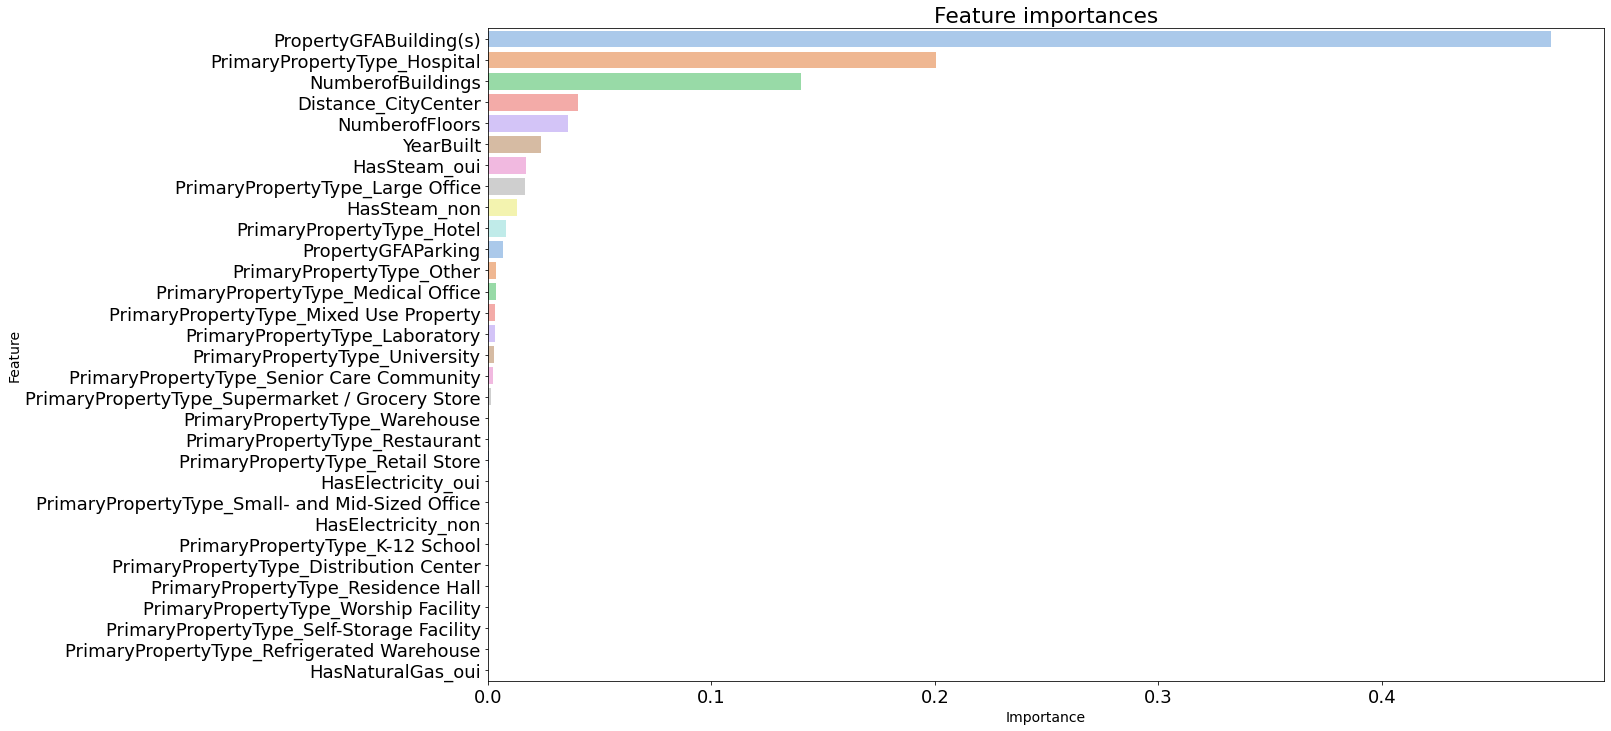

In [186]:
feature_importance(df=data_modelisation_em3, target_col="TotalGHGEmissions")

# RECAP

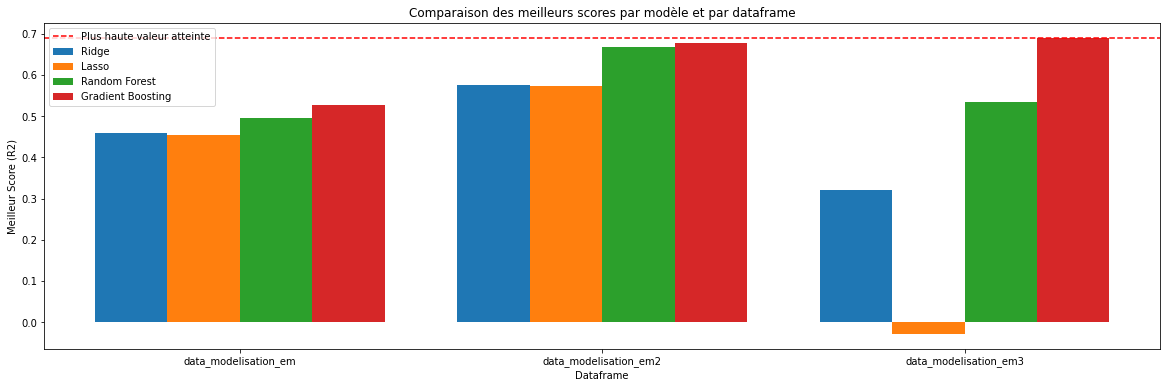

In [196]:
import matplotlib.pyplot as plt
import numpy as np

# Données des scores pour chaque modèle et chaque dataframe
dataframes = ['data_modelisation_em', 'data_modelisation_em2', 'data_modelisation_em3']
models = ['Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

scores = np.array([
    [best_score_ridge_before_fe_em, best_score_lasso_before_fe_em, best_score_rf_before_fe_em, best_score_gbr_before_fe_em],
    [best_score_ridge_fe_em, best_score_lasso_fe_em, best_score_rf_fe_em, best_score_gbr_fe_em],
    [best_score_ridge_fe2_em, best_score_lasso_fe2_em, best_score_rf_fe2_em, best_score_gbr_fe2_em]
])

# Création du graphique à barres
plt.figure(figsize=(20, 6))
bar_width = 0.2
index = np.arange(len(dataframes))

for i, model in enumerate(models):
    plt.bar(index + i * bar_width, scores[:, i], width=bar_width, label=model)

# Barre horizontale pour la plus haute valeur atteinte
max_score = np.max(scores)
plt.axhline(max_score, color='red', linestyle='--', label='Plus haute valeur atteinte')

plt.xlabel('Dataframe')
plt.ylabel('Meilleur Score (R2)')
plt.title('Comparaison des meilleurs scores par modèle et par dataframe')
plt.xticks(index + bar_width * (len(models) - 1) / 2, dataframes)
plt.legend()
plt.show()


# Evaluation EnergySTARScore


L'importance des caractéristiques dans les modèles basés sur des arbres mesure l'importance d'une caractéristique en fonction de la quantité d'impureté qu'elle peut réduire lorsqu'elle est utilisée pour diviser les nœuds. Les coefficients dans les modèles linéaires mesurent l'effet d'une augmentation d'une unité de la caractéristique sur la variable cible, en supposant que toutes les autres caractéristiques restent constantes. Ces deux mesures ont des interprétations différentes et peuvent donner des résultats différents en fonction des caractéristiques des données.

# ⭐️ENERGYSTARSCORE

In [197]:
data_modelisation_energyscore = data_clean[["Latitude","Longitude","NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)","ENERGYSTARScore"]]


In [198]:
data_modelisation_energyscore.shape

(1546, 13)

In [199]:
data_modelisation_energyscore_imputed=impute_and_normalize_data(data_modelisation_energyscore, ["TotalGHGEmissions"])

In [200]:
data_modelisation_energyscore_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1545 entries, 0 to 1545
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Latitude                1545 non-null   float64
 1   Longitude               1545 non-null   float64
 2   NumberofBuildings       1545 non-null   float64
 3   NumberofFloors          1545 non-null   float64
 4   YearBuilt               1545 non-null   float64
 5   PropertyGFAParking      1545 non-null   float64
 6   PropertyGFABuilding(s)  1545 non-null   float64
 7   Electricity(kBtu)       1545 non-null   float64
 8   NaturalGas(kBtu)        1545 non-null   float64
 9   SteamUse(kBtu)          1545 non-null   float64
 10  ENERGYSTARScore         1545 non-null   float64
 11  PrimaryPropertyType     1545 non-null   object 
 12  TotalGHGEmissions       1545 non-null   float64
dtypes: float64(12), object(1)
memory usage: 169.0+ KB


In [201]:
import folium
from folium.plugins import HeatMap

def find_city_center(df):
    # Création d'une carte avec une heatmap des émissions de gaz à effet de serre (TotalGHGEmissions)
    map_total = folium.Map(location=[df["Latitude"].mean(), df["Longitude"].mean()], zoom_start=11)
    HeatMap(data=df[["Latitude", "Longitude", "TotalGHGEmissions"]], radius=10).add_to(map_total)
    map_total.save("map_total.html")

    # Trouver la localisation la plus polluée dans le DataFrame
    lat_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Latitude"]
    lon_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Longitude"]
    print(f"La localisation la plus polluée se trouve à (latitude, longitude) = ({lat_center:.4f}, {lon_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur la localisation la plus polluée
    map_center = folium.Map(location=[lat_center, lon_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_center)
    map_center.save("map_center.html")

    # Calcul de la distance par rapport à la localisation la plus polluée
    df["Distance_Center"] = np.sqrt((df["Latitude"] - lat_center)**2 + (df["Longitude"] - lon_center)**2)

    # Interprétation de la localisation la plus polluée comme le centre-ville
    df["Distance_CityCenter"] = df["Distance_Center"].apply(lambda x: np.abs(x - df["Distance_Center"].mean()))
    lat_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Latitude"]
    lon_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Longitude"]
    print(f"Le centre-ville est interprété comme la localisation à (latitude, longitude) = ({lat_city_center:.4f}, {lon_city_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur le centre-ville
    map_city_center = folium.Map(location=[lat_city_center, lon_city_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_city_center)
    map_city_center.save("map_city_center.html")


In [202]:
data_modelisation_energyscore.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1546 entries, 0 to 1545
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Latitude                1546 non-null   float64
 1   Longitude               1546 non-null   float64
 2   NumberofBuildings       1546 non-null   float64
 3   NumberofFloors          1546 non-null   int64  
 4   YearBuilt               1546 non-null   int64  
 5   PropertyGFAParking      1546 non-null   int64  
 6   PropertyGFABuilding(s)  1546 non-null   int64  
 7   PrimaryPropertyType     1546 non-null   object 
 8   TotalGHGEmissions       1545 non-null   float64
 9   Electricity(kBtu)       1545 non-null   float64
 10  NaturalGas(kBtu)        1546 non-null   float64
 11  SteamUse(kBtu)          1546 non-null   float64
 12  ENERGYSTARScore         996 non-null    float64
dtypes: float64(8), int64(4), object(1)
memory usage: 157.1+ KB


In [203]:
find_city_center(data_modelisation_energyscore_imputed)

La localisation la plus polluée se trouve à (latitude, longitude) = (47.5349, -122.3179)
Le centre-ville est interprété comme la localisation à (latitude, longitude) = (47.6164, -122.3509)


In [204]:
data_modelisation_energyscore = data_modelisation_energyscore_imputed[["Distance_CityCenter","NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)",'TotalGHGEmissions',"ENERGYSTARScore"]]


In [205]:
data_modelisation_energyscore['HasElectricity'] = data_modelisation_energyscore['Electricity(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_energyscore['HasNaturalGas'] = data_modelisation_energyscore['NaturalGas(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_energyscore['HasSteam'] = data_modelisation_energyscore['SteamUse(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_energyscore = data_modelisation_energyscore.drop(['Electricity(kBtu)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)'], axis=1)


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [206]:
data_modelisation_energyscore

,Distance_CityCenter,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,ENERGYSTARScore,HasElectricity,HasNaturalGas,HasSteam
0,0.007980,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,60.0,oui,oui,oui
1,0.007955,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,61.0,oui,oui,non
2,0.006278,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,43.0,oui,oui,oui
3,0.006442,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,56.0,oui,oui,oui
4,0.005831,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,75.0,oui,oui,non
...,...,...,...,...,...,...,...,...,...,...,...,...
1541,0.031004,1.0,1.0,1982.0,0.0,18261.0,Other,20.33,54.8,oui,oui,non
1542,0.026305,1.0,1.0,2004.0,0.0,16000.0,Other,32.17,53.6,oui,oui,non
1543,0.021268,1.0,1.0,1974.0,0.0,13157.0,Other,223.54,50.6,oui,oui,non
1544,0.078603,1.0,1.0,1989.0,0.0,14101.0,Mixed Use Property,22.11,35.4,oui,oui,non


In [207]:
data_modelisation_energyscore.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1545 entries, 0 to 1545
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Distance_CityCenter     1545 non-null   float64
 1   NumberofBuildings       1545 non-null   float64
 2   NumberofFloors          1545 non-null   float64
 3   YearBuilt               1545 non-null   float64
 4   PropertyGFAParking      1545 non-null   float64
 5   PropertyGFABuilding(s)  1545 non-null   float64
 6   PrimaryPropertyType     1545 non-null   object 
 7   TotalGHGEmissions       1545 non-null   float64
 8   ENERGYSTARScore         1545 non-null   float64
 9   HasElectricity          1545 non-null   object 
 10  HasNaturalGas           1545 non-null   object 
 11  HasSteam                1545 non-null   object 
dtypes: float64(8), object(4)
memory usage: 189.2+ KB


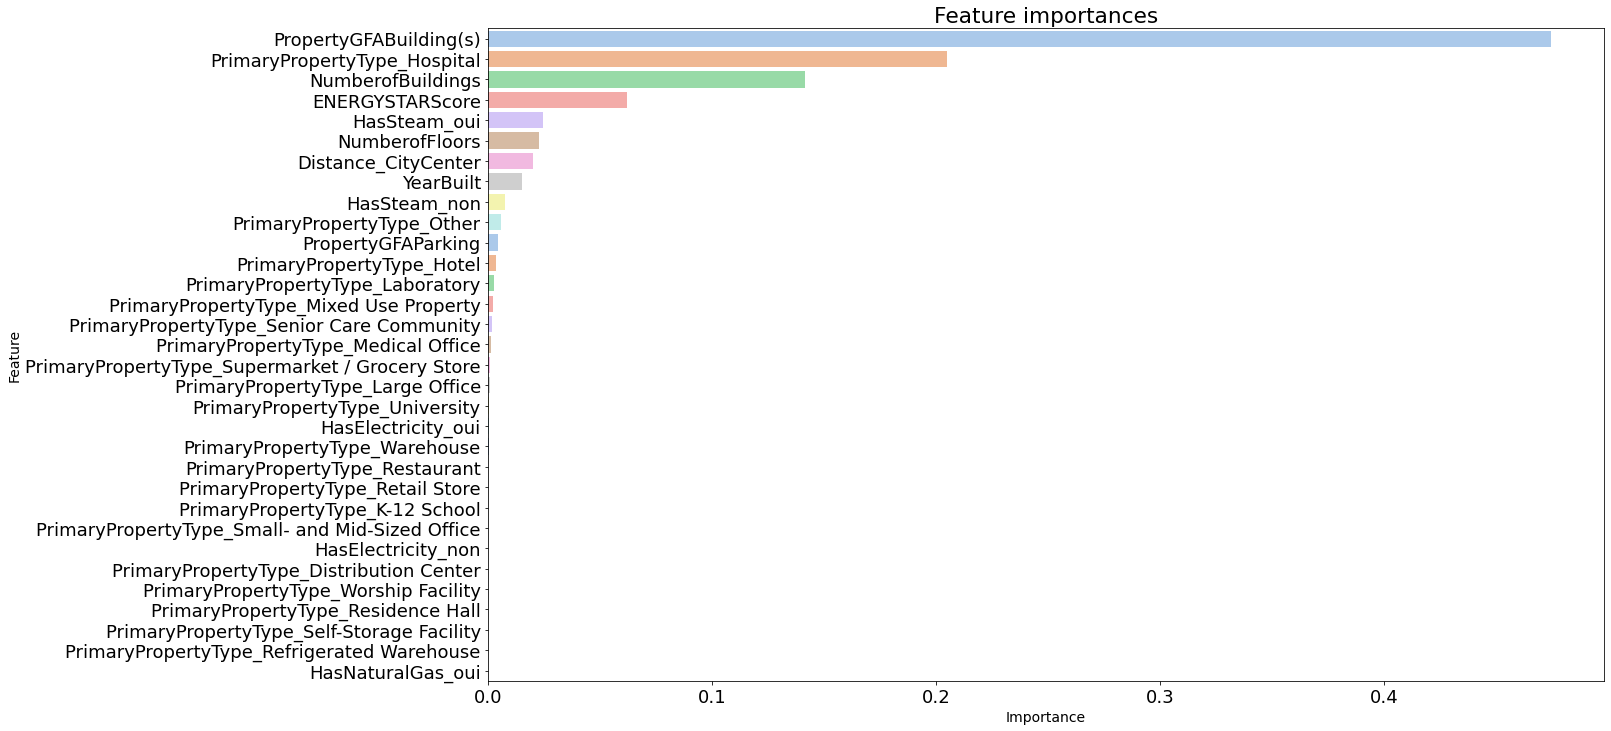

In [208]:
feature_importance(df=data_modelisation_energyscore, target_col="TotalGHGEmissions")

In [209]:
data_modelisation_energyscore

,Distance_CityCenter,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,ENERGYSTARScore,HasElectricity,HasNaturalGas,HasSteam
0,0.007980,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,60.0,oui,oui,oui
1,0.007955,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,61.0,oui,oui,non
2,0.006278,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,43.0,oui,oui,oui
3,0.006442,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,56.0,oui,oui,oui
4,0.005831,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,75.0,oui,oui,non
...,...,...,...,...,...,...,...,...,...,...,...,...
1541,0.031004,1.0,1.0,1982.0,0.0,18261.0,Other,20.33,54.8,oui,oui,non
1542,0.026305,1.0,1.0,2004.0,0.0,16000.0,Other,32.17,53.6,oui,oui,non
1543,0.021268,1.0,1.0,1974.0,0.0,13157.0,Other,223.54,50.6,oui,oui,non
1544,0.078603,1.0,1.0,1989.0,0.0,14101.0,Mixed Use Property,22.11,35.4,oui,oui,non


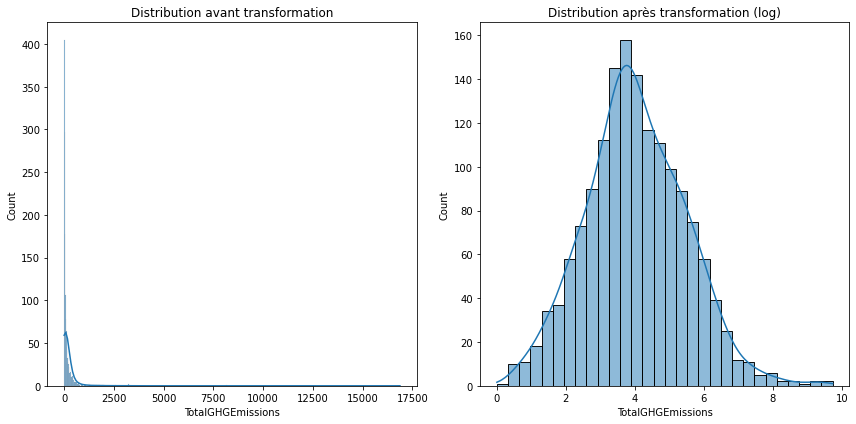

In [210]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_energyscore["TotalGHGEmissions"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_emissions_log = np.log1p(data_modelisation_energyscore["TotalGHGEmissions"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_emissions_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_energyscore_modified = data_modelisation_energyscore.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_energyscore_modified["TotalGHGEmissions"] = np.log1p(data_modelisation_energyscore_modified["TotalGHGEmissions"])

data_modelisation_energyscore = data_modelisation_energyscore_modified



In [217]:
grid_search_ridge_energystar, grid_search_lasso_energystar, grid_search_rf_energystar, grid_search_gbr_energystar, X_train_energystar, X_test_energystar, y_train_energystar, y_test_energystar = run_modeling_pipeline(df=data_modelisation_energyscore, target_col="TotalGHGEmissions", show_graphs=False, random_seed=42, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[1e-3, 1e-4, 1e-5])


Ridge - Best parameters:  {'regressor__alpha': 1.0, 'regressor__tol': 0.001}
Ridge - Best cross-validation score (R2):  0.5094489515762907
Lasso - Best parameters:  {'regressor__alpha': 0.001, 'regressor__tol': 0.001}
Lasso - Best cross-validation score (R2):  0.5056348906260049
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 0.0001, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}
RandomForestRegressor - Best cross-validation score (R2):  0.5430509573917963
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}
GradientBoostingRegressor - Best cross-validation score (R2):  0.5812906529323141


In [212]:
best_score_ridge_energystar = grid_search_ridge_energystar.best_score_
best_score_lasso_energystar = grid_search_lasso_energystar.best_score_
best_score_rf_energystar = grid_search_rf_energystar.best_score_
best_score_gbr_energystar = grid_search_gbr_energystar.best_score_

best_params_ridge_energystar = grid_search_ridge_energystar.best_params_
best_params_lasso_energystar = grid_search_lasso_energystar.best_params_
best_params_rf_energystar = grid_search_rf_energystar.best_params_
best_params_gbr_energystar = grid_search_gbr_energystar.best_params_



In [213]:
summary_energystar = display_summary([grid_search_ridge_energystar, grid_search_lasso_energystar, grid_search_rf_energystar, grid_search_gbr_energystar],
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_energystar, y_train_energystar, X_test_energystar, y_test_energystar)
summary_energystar


The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 1.0, 'regressor__tol': 0.001}",0.509449,0.563716,0.587939,0.919354,0.863491,0.958829,0.929242,0.744923,0.728038
1,Lasso,"{'regressor__alpha': 0.001, 'regressor__tol': 0.001}",0.505635,0.572247,0.616534,0.901378,0.803568,0.949409,0.896419,0.736115,0.702980
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}",0.546299,0.806665,0.555470,0.407403,0.931531,0.638281,0.965159,0.497535,0.757498
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}",0.581291,0.759186,0.600258,0.507453,0.837676,0.712358,0.915246,0.548795,0.725619


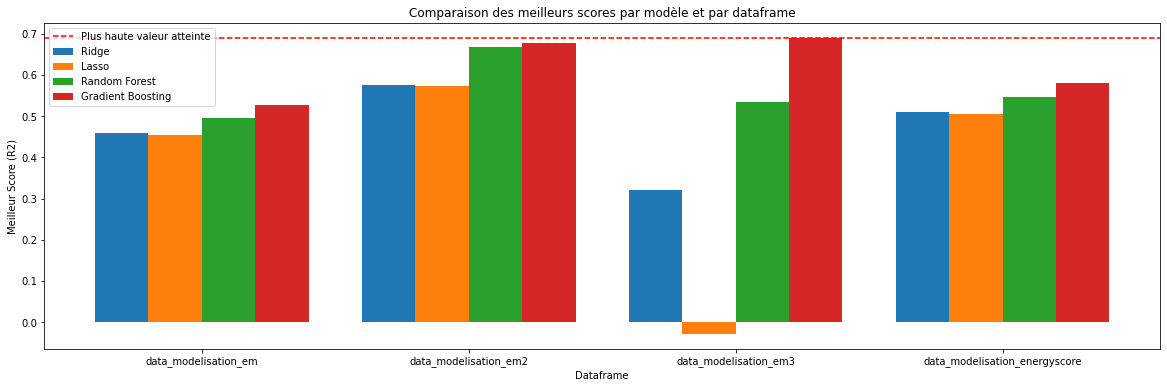

In [214]:
import matplotlib.pyplot as plt
import numpy as np

# Données des scores pour chaque modèle et chaque dataframe
dataframes = ['data_modelisation_em', 'data_modelisation_em2', 'data_modelisation_em3','data_modelisation_energyscore']
models = ['Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

scores = np.array([
    [best_score_ridge_before_fe_em, best_score_lasso_before_fe_em, best_score_rf_before_fe_em, best_score_gbr_before_fe_em],
    [best_score_ridge_fe_em, best_score_lasso_fe_em, best_score_rf_fe_em, best_score_gbr_fe_em],
    [best_score_ridge_fe2_em, best_score_lasso_fe2_em, best_score_rf_fe2_em, best_score_gbr_fe2_em],
    [best_score_ridge_energystar , best_score_lasso_energystar , best_score_rf_energystar , best_score_gbr_energystar ]
])

# Création du graphique à barres
plt.figure(figsize=(20, 6))
bar_width = 0.2
index = np.arange(len(dataframes))

for i, model in enumerate(models):
    plt.bar(index + i * bar_width, scores[:, i], width=bar_width, label=model)

# Barre horizontale pour la plus haute valeur atteinte
max_score = np.max(scores)
plt.axhline(max_score, color='red', linestyle='--', label='Plus haute valeur atteinte')

plt.xlabel('Dataframe')
plt.ylabel('Meilleur Score (R2)')
plt.title('Comparaison des meilleurs scores par modèle et par dataframe')
plt.xticks(index + bar_width * (len(models) - 1) / 2, dataframes)
plt.legend()
plt.show()


## SHAP

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


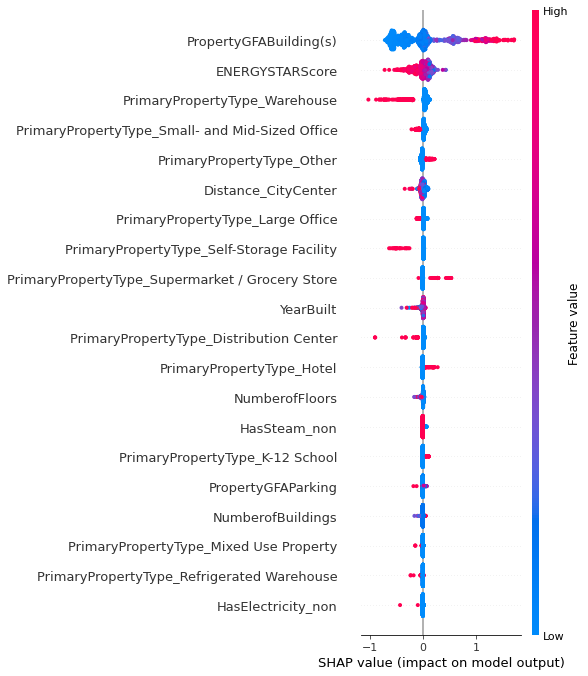

In [215]:
explainer_energystar, shap_values_energystar, X_train_encoded_energystar = calculate_shap_values(X_train_energystar, y_train_energystar)
plot_shap_summary(explainer_energystar, shap_values_energystar, X_train_encoded_energystar)
import warnings
warnings.filterwarnings('ignore')


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Les caractéristiques qui sont plus hautes sur le graphique ont un impact plus grand. <br> <br>
    Les valeurs élevées de ces caractéristiques ont tendance à augmenter ou à diminuer la prédiction selon la position des points le long de l'axe X et leur couleur.
    <br><br>
    Les points horizontaux correspondent aux valeurs de SHAP (SHAP values) associées à chaque caractéristique. Les valeurs de SHAP mesurent la contribution de chaque caractéristique à la différence entre la prédiction du modèle pour une observation donnée et la valeur de référence. Les points sont positionnés horizontalement en fonction de leur valeur de SHAP. Les caractéristiques avec des valeurs de SHAP plus élevées sont situées plus à droite, tandis que celles avec des valeurs de SHAP plus faibles sont situées plus à gauche.


</p> 